# Les Transformers — travaux pratiques
## Quatre TP pour reconstruire un mini-Transformer

| TP | Brique | Contenu |
|---|---|---|
| 1 | Données et bigramme | tokeniser, former les cibles, entraîner une table |
| 2 | Auto-attention | agréger, masquer le futur, calculer $QK^\top$ |
| 3 | LayerNorm et MLP | normaliser, activer des neurones, préserver la dimension |
| 4 | Modèle complet | assembler, évaluer la loss, générer du texte |

In [1]:
!pip install torch 


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install matplotlib


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, torch
import torch.nn as nn
import torch.nn.functional as F
from urllib.request import urlretrieve

print(torch.__version__)

2.14.1+cpu


---
# TP 1 — Du texte brut au premier modèle bigramme

## Étape 1 — Télécharger et inspecter le corpus
Relevez : la longueur du corpus, les retours à la ligne, la ponctuation, les majuscules/minuscules.

In [4]:
url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
print(os.path.abspath("input.txt"))

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))
print(text[:1000])

c:\Users\arthu\Documents\Travail\Boulot\ING3\S1\NLP\tp transfo\input.txt
1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes:

**Questions d'interprétation**

Quelle est ici l'unité d'un token ? Pourquoi préciser `encoding="utf-8"` ? Le fichier est-il déjà séparé en exemples ?

**Réponse :** 
> Unité d'un token : Ici, c'est le caractère individuel (lettres, chiffres, signes de ponctuation, espaces, retours à la ligne).

> encoding="utf-8" garantit que les caractères accentués ou spéciaux présents dans le texte brut (comme les pièces de Shakespeare) sont correctement lus et décodés sans erreur d'encodage.

> Non, le fichier n'est pas séparé, c'est un bloc de texte brut continu, sans séparation préalable en exemples d'entraînement distincts. C'est le découpage en blocs (via block_size) qui va créer les séquences d'apprentissage.

> Relevé : le corpus contient 1 115 394 caractères. Les retours à la ligne séparent les vers et une ligne vide sépare deux répliques ; ce sont des caractères comme les autres. La ponctuation est présente (`, . ; : ? ! ' -`), les noms de personnages sont en majuscules suivis de `:`, et le reste du texte est en minuscules, avec une majuscule en début de phrase.

## Étape 2 — Des caractères aux entiers
On construit un vocabulaire puis deux dictionnaires parfaitement inverses.

In [5]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print("".join(chars), vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join([itos[i] for i in ids])

message = "hii there"
print(encode(message))
print(decode(encode(message)))
assert decode(encode(message)) == message


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz 65
[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


**Questions d'interprétation**

Pourquoi trier `chars` ? Que garantit le test `decode(encode(message)) == message` ?

> On trie la liste unique des caractères pour garantir un ordre déterministe et stable pour la création du vocabulaire et l'attribution des indices (de 0 à $C-1$), garantissant la reproductibilité de l'encodage.

> Le test valide la stricte inversion des dictionnaires stoi et itos. Encoder puis décoder une chaîne doit restituer exactement la chaîne originale sans perte d'information.

## Étape 3 — Fabriquer les prédictions attendues
Une séquence de longueur $T+1$ fournit une entrée $x$ et une cible $y$ décalée d'une position : chaque token doit prédire le suivant.

In [6]:
data = torch.tensor(encode(text), dtype=torch.long)

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]

for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    print(context.tolist(), "->", target.item())

[18] -> 47
[18, 47] -> 56
[18, 47, 56] -> 57
[18, 47, 56, 57] -> 58
[18, 47, 56, 57, 58] -> 1
[18, 47, 56, 57, 58, 1] -> 15
[18, 47, 56, 57, 58, 1, 15] -> 47
[18, 47, 56, 57, 58, 1, 15, 47] -> 58


**Questions d'interprétation**

1. Combien de prédictions produit ce bloc ?
2. Pourquoi ne pas mélanger train et validation ?
3. Pour $t=3$, quels sont le contexte et la cible ?

**Réponse :**

> Un bloc de 8 caractères donne 8 prédictions : à chaque position, on prédit le caractère qui suit.
>
> Je garde le jeu de validation à part pour vérifier si le modèle sait prédire du texte qu’il n’a pas vu pendant l’entraînement.
>
> Pour $t=3$, le contexte est `x[:4]` (les positions 0 à 3) et la cible est `y[3]`, c’est-à-dire le caractère suivant.

## Étape 4 — Échantillonner un mini-batch
$x_b, y_b \in \mathbb{N}^{B\times T}$ : une ligne = une séquence indépendante, une colonne = une position temporelle.

In [7]:
batch_size = 4
block_size = 8

def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])
    return x, y

xb, yb = get_batch("train")
print(xb.shape, yb.shape)
print(xb)
print(yb)

torch.Size([4, 8]) torch.Size([4, 8])
tensor([[58, 46, 47, 57,  1, 41, 53, 51],
        [15, 39, 51, 47, 50, 50, 53,  6],
        [39, 52, 42,  1, 61, 43,  1, 40],
        [58, 12,  1, 35, 46, 39, 58,  6]])
tensor([[46, 47, 57,  1, 41, 53, 51, 47],
        [39, 51, 47, 50, 50, 53,  6,  1],
        [52, 42,  1, 61, 43,  1, 40, 53],
        [12,  1, 35, 46, 39, 58,  6,  0]])


**Questions d'interprétation**

1. Pourquoi retirer `block_size` à la borne de tirage ?
2. Que changerait $B=32$ ?
3. Que changerait $T=64$ ?

**Réponse :**

> On retire `block_size` à la borne pour pouvoir prendre les `block_size + 1` caractères nécessaires à `x` et `y`, sans dépasser la fin du corpus.
>
> Avec $B=32$, on traiterait 32 séquences à la fois au lieu de 4. L’estimation du gradient serait généralement plus stable, mais il faudrait davantage de mémoire.
>
> Avec $T=64$, chaque séquence donnerait au modèle un contexte plus long. En contrepartie, le calcul serait plus lourd.

## Étape 5 — Une table produit les logits
$(B,T) \longrightarrow (B,T,C)$ : chaque caractère choisit une ligne contenant un score pour chacun des $C$ caractères possibles.

In [8]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)
        # idx: (B,T) -> logits: (B, T, C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

model = BigramLanguageModel(vocab_size)
logits, loss = model(xb, yb)
print(logits.shape, loss.item())   # loss attendue au départ ~ ln(65) ≈ 4.17

torch.Size([32, 65]) 5.025188446044922


**Questions d'interprétation**

Pourquoi une table $C\times C$ ici ? Où retrouvera-t-on $d_{emb}$ et la couche `lm_head` dans le TP 4 ?

**Réponse :**

> La table a $C$ lignes, une par caractère du vocabulaire, et $C$ colonnes pour les scores des caractères suivants. Ici, l’embedding sert directement à produire les logits du bigramme.
>
> Dans le TP 4, les embeddings ont une dimension cachée $n_{embd}$, indépendante de la taille du vocabulaire. C’est `lm_head` qui transforme ensuite cette représentation en scores sur les $C$ caractères possibles.

## Étapes 6 et 7 — Générer, puis apprendre

In [9]:
def sample(model, n=300):
    ctx = torch.zeros((1, 1), dtype=torch.long)
    return decode(model.generate(ctx, max_new_tokens=n)[0].tolist())

print("=== AVANT entraînement ===")
print(sample(model))

=== AVANT entraînement ===

rb-N!PZJHCUvrAh
MdwxW
NxkNFK.PNNc'vGxbMyISjXf'!jO$&dlXWM'yIZ&?CWS$3GQnrdjS duQnJYPWwi!duyN xdMU'!k $P!dZrXatbkfyx,.YY j:lCCNAOyNxbCIbN;aPdM?hG?EBTgdw$z ijvuGN:hGDJkoiWu.yGMkAK.:S'-nRHWaZUDvq!oqgW3CYfOEjY YWFSbeYWeod;JKZymbCZPFfzHyG.QUumzqLA'BYFz.LQBS iBnvPv?IZNmaO&I:LoumnpN!fc$qr-wB$AgRuo;yhIfQyLyyN


In [10]:
batch_size = 32
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

for step in range(100):
    xb, yb = get_batch("train")
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
print(loss.item())
print("=== APRÈS 100 étapes ===")
print(sample(model))

4.469082355499268
=== APRÈS 100 étapes ===

IUSarBWHmPS yw-ebFb?&IFSpbKB!HeISWMSA SfwQcJ?S;oXdv?h xJlSNq;AV,EC:lgkv.QVh,FwRLqCrduR xwQnzk$l.ID:B3VwIEVwwq!?pRs: ;RglfvMCpgPLvjfmba&o-swfh
MOaaaEYPWh,msb?dDYAGetRRUvOfNYg$ppo&kTRGjN d;;Je; ZOyCY.PdMl3,cOc$.3Mn?gEDMd;A'pqyGocHwlBSOywwQVvMZN?hG&INhIUjcHWm$liot!fdGuy?pvBYYBTuihrd3ziqSTkAro; Y-N?ITkS


In [11]:
for step in range(1000):
    xb, yb = get_batch("train")
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
print(loss.item())
print("=== APRÈS 1 000 étapes supplémentaires ===")
print(sample(model))

3.527418851852417
=== APRÈS 1 000 étapes supplémentaires ===

Sx&x,oqydu'ZgitasRQ' M?&sstot:.Bhtq! SpoaRcPWad;RA&MdAV,QnKn,sC:.CUSePd,ED3rX:&pot:N$!sGaBykoeeZPPFYBFlk3-v-'kzfAWaRStheo!nbC?FXdUDQn'3,
N$TbJ;A
nd!t,sDUKCjd;oNpTqAu; e
 mbjXb,
bcZC?.sUjvc;; vienfXf
uP
PdiAndePithuKw;&ld;JEMatHemaZliPJHWxEakPdX3Tke S QnISTakTi&t:Mh
vgMPdEYRWiekHSZEV.CoT!fxMNByaPdb,N


**Bilan du TP 1** — Pourquoi ne garde-t-on que le dernier pas de temps pendant la génération ? Pourquoi aplatit-on $B\times T$ pendant la loss ? Comparez la loss et la structure du texte avant/après 100 étapes, puis avec 1 000 étapes.

**Réponse :**

> En génération, on ne garde que les logits du dernier pas de temps : ils donnent la distribution utilisée pour choisir le prochain caractère. Pendant l’entraînement, on garde les logits de toutes les positions, puis on aplatit $B\times T$ pour les donner à `CrossEntropyLoss`, qui attend une ligne par prédiction.
>
> Au départ, la loss est proche de celle d’un choix au hasard (environ $\ln(65)\approx4{,}17$ si le vocabulaire contient 65 caractères) et le texte généré est peu lisible. Elle baisse avec l’entraînement ; après 100 puis 1 000 étapes, on commence à voir apparaître des espaces, de la ponctuation et de petites structures qui ressemblent au corpus.

---
# TP 2 — Construire l'auto-attention pas à pas

**Objectif :** partir d'une moyenne des tokens précédents et arriver à une tête qui apprend elle-même quels tokens contribuent.

`Boucles (moyenne causale)` → `Produit matriciel (poids fixes)` → `Masque + Softmax` → `Self-attention (poids appris)`

**Invariant :** une ligne de poids contient la contribution des tokens passés au token courant, et sa somme vaut toujours 1.

## Étape 1 — Agréger par produit matriciel
$c_t = \sum_i a_{t,i}\, b_i$

In [12]:
torch.manual_seed(42)

a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)

b = torch.randint(0, 10, (3, 2)).float()
c = a @ b

print(a)
print(b)
print(c)

tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


**Questions d'interprétation**

Sans Python, calculez $c_2$. Pourquoi la somme de chaque ligne de `a` vaut-elle 1 ?

**Réponse :**

> La dernière ligne de `a` vaut $[1/3,1/3,1/3]$, donc $c_2$ est la moyenne des trois lignes de `b` : $[(2+6+6)/3,(7+4+5)/3]$, soit environ $[4{,}67,5{,}33]$.
>
> Chaque ligne de `a` est divisée par sa somme. Les poids d’une ligne font donc 1.

## Étape 2 — Moyenner uniquement le passé

In [13]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t+1]          # forme ?
        xbow[b, t] = torch.mean(xprev, dim=0)

print(xprev.shape)

torch.Size([8, 2])


**Questions d'interprétation**

Donnez les formes de `xprev` pour $t=0$, $t=3$ et $t=7$. Pourquoi la moyenne porte-t-elle sur `dim=0` ?

**Réponse :**

> Pour $t=0$, `xprev` a la forme $(1,C)$ ; pour $t=3$, $(4,C)$ ; et pour $t=7$, $(8,C)$. La première dimension correspond au nombre de positions déjà prises en compte.
>
> On fait la moyenne sur `dim=0` parce que c’est l’axe du temps : on regroupe ainsi les vecteurs des tokens passés, sans réduire la dimension des caractéristiques.

## Étapes 3–4 — Vectoriser : matrice triangulaire, puis masque $-\infty$ + Softmax

In [14]:
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x
print(torch.allclose(xbow, xbow2, atol=1e-6))

tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float("-inf"))
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
print(torch.allclose(xbow, xbow3, atol=1e-6))

True
True


**Questions d'interprétation**

Pourquoi `wei @ x` fonctionne-t-il avec une matrice $(T,T)$ et un tenseur $(B,T,C)$ ? Que devient Softmax aux emplacements contenant $-\infty$ ?

**Réponse :**

> La multiplication fonctionne parce que PyTorch diffuse la matrice $(T,T)$ sur les $B$ séquences du batch : les mêmes poids sont appliqués séparément à chacune d’elles.
>
> Dans Softmax, les emplacements à $-\infty$ deviennent des poids nuls. Les tokens futurs ne contribuent donc pas au résultat.

## Étape 5 — Calculer des poids d'attention
Les poids viennent de la compatibilité entre queries et keys.

In [15]:
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
head_size = 16

key   = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)      # (B,T,head_size)
q = query(x)    # (B,T,head_size)
wei = q @ k.transpose(-2, -1)    # (B,T,T)
wei = wei * head_size**-0.5    # mise à l'échelle
tril = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(tril == 0, float("-inf"))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v                   # (B,T,head_size)

print(wei.shape, out.shape)
print(wei[0])
print("sommes des lignes :", wei.sum(-1)[0])
print("poids vers le futur nuls :", bool((wei.triu(1) == 0).all()))

torch.Size([4, 8, 8]) torch.Size([4, 8, 16])
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3966, 0.6034, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3069, 0.2892, 0.4039, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3233, 0.2175, 0.2443, 0.2149, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1479, 0.2034, 0.1663, 0.1455, 0.3369, 0.0000, 0.0000, 0.0000],
        [0.1259, 0.2490, 0.1324, 0.1062, 0.3141, 0.0724, 0.0000, 0.0000],
        [0.1598, 0.1990, 0.1140, 0.1125, 0.1418, 0.1669, 0.1061, 0.0000],
        [0.0845, 0.1197, 0.1078, 0.1537, 0.1086, 0.1146, 0.1558, 0.1553]],
       grad_fn=<SelectBackward0>)
sommes des lignes : tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<SelectBackward0>)
poids vers le futur nuls : True


**Questions d'interprétation**

Quelle ligne de `wei[0]` correspond au dernier token ? Pourquoi la sortie mélange-t-elle $v$ et non directement $k$ ?

**Réponse :**

> La ligne d’indice 7, `wei[0, 7]`, correspond au dernier token de la séquence : il peut regarder les huit positions, puisque toutes sont dans son passé ou à sa position.
>
> `Q` et `K` servent à calculer les poids d’attention. Ce sont les vecteurs `V` qui portent l’information ensuite combinée avec ces poids.

## Étape 6 — Stabiliser Softmax
$\mathrm{Var}(qk^\top)\approx d_h \Rightarrow \mathrm{Var}\!\left(qk^\top/\sqrt{d_h}\right)\approx 1$

In [16]:
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)

raw = q @ k.transpose(-2, -1)
scaled = raw * head_size**-0.5
print(raw.var(), scaled.var())

z = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
print(torch.softmax(z, dim=-1))
print(torch.softmax(z * 8, dim=-1))

tensor(17.4690) tensor(1.0918)
tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


**Bilan du TP 2** — Vérifiez la somme des lignes de `wei`, l'absence de poids vers le futur et la forme finale. Expliquez le rôle distinct de $Q$, $K$ et $V$.

**Réponse :**

> Chaque ligne de `wei` a une somme égale à 1 grâce au Softmax, et les poids associés aux positions futures sont nuls grâce au masque causal. La sortie a la forme $(B,T,d_h)$.
>
> `Q` indique ce que le token cherche, `K` permet de mesurer si les autres tokens correspondent à cette recherche, et `V` contient l’information effectivement récupérée.

> Formes : $x:(B,T,C)$, puis $q,k,v:(B,T,d_h)$, `wei` : $(B,T,T)$ et la sortie $(B,T,d_h)$. Dans l'exemple, $(4,8,32)\to(4,8,16)$ avec $d_h=16$.

---
# TP 3 — Stabiliser puis transformer chaque token

**Objectif :** implémenter une LayerNorm, comprendre son axe de calcul, puis construire le MLP appliqué séparément à chaque token.

`Vecteur Eᵢ (dim C)` → `LayerNorm` → `Feed-forward C→4C→C` → `Eᵢ + ΔEᵢ (résiduel)`

## Étape 1 — Coder LayerNorm
$\hat x_{i,j}=\dfrac{x_{i,j}-\mu_i}{\sqrt{\sigma_i^2+\varepsilon}},\quad y_{i,j}=\gamma_j\hat x_{i,j}+\beta_j$

In [17]:
class LayerNorm1d:
    def __init__(self, dim, eps=1e-5):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

    def __call__(self, x):
        xmean = x.mean(dim=-1, keepdim=True)
        xvar = x.var(dim=-1, keepdim=True, unbiased=False)
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        return self.gamma * xhat + self.beta

**Questions d'interprétation**

Sur quel axe normaliser ? À quoi servent $\varepsilon$, $\gamma$ et $\beta$ ?

**Réponse :**

> On normalise sur la dernière dimension (`dim=-1`), donc sur les caractéristiques d’un token. $\varepsilon$ évite une division instable quand la variance est très faible. Dans une couche LayerNorm complète, $\gamma$ et $\beta$ sont des paramètres appris qui règlent l’échelle et le décalage ; dans la version simplifiée du notebook, ils sont initialisés à 1 et 0 pour montrer le calcul.

## Étape 2 — Choisir l'axe de normalisation
**Prédisez** quelle ligne donnera environ $(0,1)$ avant d'exécuter.

In [18]:
torch.manual_seed(1337)
module = LayerNorm1d(100)

x = torch.randn(32, 100)
y = module(x)

print(y[:, 0].mean(), y[:, 0].std())   # les 32 tokens, feature 0
print(y[0, :].mean(), y[0, :].std())   # les 100 features du token 0

print(torch.allclose(y, nn.LayerNorm(100)(x), atol=1e-6))

tensor(0.1476) tensor(0.8847)
tensor(-2.2650e-08) tensor(1.0050)
True


**Réponse :**

> La ligne `y[0, :]` donne environ $(0,1)$ : la LayerNorm normalise sur la dernière dimension, donc les 100 caractéristiques d'un même token ont une moyenne nulle et un écart-type proche de 1 (ici $-2{,}3\times10^{-8}$ et $1{,}005$).

> La ligne `y[:, 0]` regroupe la caractéristique 0 de 32 tokens différents. Ces valeurs ne sont pas normalisées entre elles, d'où une moyenne de $0{,}15$ et un écart-type de $0{,}88$.

> L'écart-type de $1{,}005$ et non $1$ vient de `torch.std`, qui divise par $n-1$, alors que la LayerNorm utilise la variance avec $n$ (`unbiased=False`) : $\sqrt{100/99}\approx1{,}005$. Le test `allclose` avec `nn.LayerNorm` vaut `True`, donc le calcul est correct.

## Étape 3 — Le réseau feed-forward

In [19]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, x):
        return self.net(x)

ffwd = FeedForward(100)
delta = ffwd(torch.randn(32, 100))
print(delta.shape)

h = F.relu(ffwd.net[0](torch.randn(32, 100)))
print("proportion d'activations positives :", (h > 0).float().mean().item())

torch.Size([32, 100])
proportion d'activations positives : 0.4953906238079071


**Questions d'interprétation**

Quelle proportion d'activations est positive ? Pourquoi revenir à $C$ ?

**Réponse :**

> Avec ReLU, on s’attend à ce qu’environ la moitié des activations soient positives ; dans l’exemple exécuté, on en obtient environ 0,495.
>
> Le MLP élargit d’abord la représentation de $C$ à $4C$, puis revient à $C$. Cette dimension est nécessaire pour pouvoir additionner sa sortie à l’entrée avec la connexion résiduelle.

## Étapes 4 et 5 — Ajouter le résiduel (pré-norm)

In [20]:
B, T, n_embd = 4, 8, 32
layer_norm = nn.LayerNorm(n_embd)
ffwd = FeedForward(n_embd)
x = torch.randn(B, T, n_embd)

delta = ffwd(layer_norm(x))
x_out = x + delta
print(x.shape)
print(delta.shape)
print(x_out.shape)

torch.Size([4, 8, 32])
torch.Size([4, 8, 32])
torch.Size([4, 8, 32])


**Variantes à tester**
1. Remplacer `ReLU` par `GELU`.
2. Tester $C\to 2C\to C$, puis $C\to 8C\to C$.
3. Compter les paramètres dans chaque cas.
4. Retirer l'addition résiduelle et comparer les formes.

**Réponse :**

> Remplacer `ReLU` par `GELU` ne change ni les formes ni le nombre de paramètres, car l'activation n'a aucun paramètre appris. GELU est une version lissée de ReLU : les valeurs négatives ne sont plus mises exactement à 0, elles sont seulement atténuées.

> Avec $C=32$, on obtient 4 192 paramètres pour $C\to2C\to C$, 8 352 pour $C\to4C\to C$ et 16 672 pour $C\to8C\to C$. Pour un multiplicateur $m$, le total vaut $2mC^2+(m+1)C$ : il est dominé par les deux matrices de poids, donc il double à peu près quand $m$ double.

> Sans l'addition résiduelle, `x_out = delta` garde la forme $(B,T,C)$ : les formes ne permettent donc pas de voir la différence. Ce qui change, c'est que la représentation d'entrée de chaque token n'est plus conservée (le MLP la remplace) et que le gradient doit traverser toute la sous-couche.

In [21]:
def make_ffwd(n_embd, mult=4, act=nn.ReLU):
    return nn.Sequential(nn.Linear(n_embd, mult*n_embd), act(), nn.Linear(mult*n_embd, n_embd))

for mult in (2, 4, 8):
    for act in (nn.ReLU, nn.GELU):
        m = make_ffwd(n_embd, mult, act)
        print(f"C->{mult}C->C, {act.__name__:5s}:", sum(p.numel() for p in m.parameters()), "paramètres")

C->2C->C, ReLU : 4192 paramètres
C->2C->C, GELU : 4192 paramètres
C->4C->C, ReLU : 8352 paramètres
C->4C->C, GELU : 8352 paramètres
C->8C->C, ReLU : 16672 paramètres
C->8C->C, GELU : 16672 paramètres


**Bilan du TP 3** — Quelle dimension LayerNorm conserve-t-elle ? Le MLP mélange-t-il les tokens ? À quoi sert la connexion résiduelle ?

**Réponse :**

> LayerNorm garde la forme $(B,T,C)$ : elle normalise les caractéristiques de chaque token sans changer leur nombre. Le MLP transforme chaque token séparément, il ne mélange donc pas les tokens entre eux.
>
> La connexion résiduelle ajoute l’entrée à la sortie de la sous-couche. Elle conserve la dimension et aide le gradient à circuler dans les couches du modèle.

---
# TP 4 — Assembler et entraîner le modèle complet

`Tokens (+ positions)` → `Attention multi-têtes` → `LayerNorm et MLP` (×4 blocs résiduels) → `Unembedding et Softmax`

In [22]:
batch_size = 16
block_size = 32
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)

# get_batch (TP1) redéfini avec les nouvelles constantes, sortie sur le bon device
def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)

cpu


**Questions d'interprétation**

Calculez $d_h = n_{emb}/n_{head}$. Combien de tokens contient un batch ? Sur CPU, quelle variable réduiriez-vous d'abord pour tester ?

**Réponse :**

> $d_h=n_{embd}/n_{head}=64/4=16$. Un batch contient $16\times32=512$ tokens.
>
> Sur CPU, je réduirais d’abord `max_iters` pour faire un essai plus rapide, par exemple à 500.

## Étape 1 — Coder une tête
Pour $x$ de forme $(16,32,64)$ : $q,k,v:(16,32,16)$ ; `wei` : $(16,32,32)$ ; sortie : $(16,32,16)$.

In [23]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

**Questions d'interprétation**

Pourquoi utiliser `k.size(-1)` plutôt que `C` pour le facteur d'échelle ? Pourquoi tronquer `tril[:T,:T]` ?

**Réponse :**

> `k.size(-1)` donne la dimension de la tête ($d_h$), celle qui intervient dans le produit $QK^\top$. On divise par sa racine carrée pour stabiliser les scores avant le Softmax.
>
> `tril` est créé à la taille maximale `block_size`. On le découpe en `[:T, :T]` pour qu’il corresponde à la longueur réelle de la séquence.

## Étape 2 — Combiner plusieurs têtes

In [24]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

**Questions d'interprétation**

Pourquoi concaténer sur la dernière dimension ? Quel problème aurait-on si $n_{emb}$ n'était pas divisible par $n_{head}$ ?

**Réponse :**

> Chaque tête produit un vecteur de taille $d_h$. En concaténant sur la dernière dimension, on réunit leurs sorties et on retrouve $n_{head}\times d_h=n_{embd}$ caractéristiques.
>
> Si $n_{embd}$ n’était pas divisible par $n_{head}$, on ne pourrait pas répartir la dimension de façon égale entre les têtes.

## Étape 3 — Assembler un bloc

In [25]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4*n_embd),
            nn.ReLU(),
            nn.Linear(4*n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

**Questions d'interprétation**

Dans quel ordre appliquer LayerNorm, attention/MLP et addition ? À quelle opération correspondent « communication » et « calcul » ?

**Réponse :**

> On normalise d’abord avec LayerNorm, puis on applique l’attention ou le MLP, et enfin on ajoute le résultat à l’entrée grâce à la connexion résiduelle : c’est le pré-norm utilisé ici.
>
> L’attention assure la communication entre les tokens ; le MLP fait le calcul sur les caractéristiques de chaque token.

## Étapes 4, 5 et 6 — Couches, passage avant, loss et génération

In [26]:
class TransformerLanguageModel(nn.Module):   #  BigramLanguageModel  dans l'énoncé
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)                 # (B,T,n_embd)
        pos = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding_table(pos)              # (T,n_embd)

        x = tok_emb + pos_emb                                   # (B,T,C)
        x = self.blocks(x)                                        # (B,T,C)
        x = self.ln_f(x)
        logits = self.lm_head(x)                                  # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            logits = logits.reshape(B*T, vocab_size)
            targets = targets.reshape(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

**Questions d'interprétation**

Donnez les dimensions des trois matrices d'embedding/unembedding. Quelle règle de broadcasting permet l'addition des embeddings ? Pourquoi `@torch.no_grad()` ? Pourquoi `multinomial` plutôt que `argmax` ?

**Réponse :**

> `token_embedding_table` a la forme $(vocab\_size,n_{embd})$ et `position_embedding_table` la forme $(block\_size,n_{embd})$. `lm_head` transforme un vecteur de $n_{embd}$ caractéristiques en $vocab\_size$ logits ; dans PyTorch, son poids est stocké avec la forme $(vocab\_size,n_{embd})$.
>
> L’embedding de position a la forme $(T,n_{embd})$ et s’ajoute à celui des tokens $(B,T,n_{embd})$ : PyTorch diffuse automatiquement la dimension du batch.
>
> `@torch.no_grad()` évite de calculer des gradients pendant l’évaluation et la génération. `multinomial` tire un token selon les probabilités, alors qu’`argmax` choisirait toujours le plus probable.

> `lm_head` n'est plus confondu avec l'embedding : dans le bigramme, la même table $C\times C$ servait à lire le caractère et à produire les scores. Ici, l'embedding $(C,n_{embd})$ représente le caractère, les blocs le contextualisent, puis `lm_head` le convertit en $C$ scores. Ce sont deux matrices distinctes, et $n_{embd}$ ne dépend plus de la taille du vocabulaire.

> On n'aplatit pas les logits pendant la génération : il n'y a pas de cibles, et on garde la forme $(B,T,C)$ pour prendre `logits[:, -1, :]`, le dernier pas de temps de chaque séquence. Aplatir en $(B\times T,C)$ mélangerait les séquences et les positions ; cela ne sert que pour la loss.

> `idx[:, -block_size:]` coupe le contexte à la fin parce que la table de positions n'a que `block_size` lignes : le modèle ne sait pas traiter plus de $T=$ `block_size` tokens.

## Étapes 7 et 8 — Évaluer puis entraîner

In [27]:
model = TransformerLanguageModel().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M paramètres")

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

context = torch.zeros((1, 1), dtype=torch.long, device=device)
print("=== AVANT entraînement ===")
print(decode(model.generate(context, max_new_tokens=300)[0].tolist()))

0.209729 M paramètres
=== AVANT entraînement ===



,'Joe$IFikSsxYxDGFhSCw-o$r$di ''WB::DBBGH,jZAipF$dLUfdBbfBQJeG?TB Jv'x:efr-tb&ohbxypB'Ejb B:hSd?Z?Y:TwtFkyb
c!:,XD& Z.L?uB$'EIDB'XAIUOpBf3CqP.Z$B:a'NT,JAgxghn. 
jt:ZVnyI:'ZN$MeCgtZh,qxhpSaxgphz.tCxqDSB&WXzRqf!Xkh
a$r$MjwH,hJRQVC
B-3kbVTePPJvflgyBfzLORULJSBHqBqSAh-$r
QqNWZz-EIo:':BpJ
y':-i IBq&e,EgJO


In [28]:
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
history = []

for iteration in range(max_iters):
    if iteration % eval_interval == 0:
        l = estimate_loss()
        history.append((iteration, l['train'], l['val']))
        print(f"étape {iteration}: train {l['train']:.4f}, val {l['val']:.4f}")

    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

étape 0: train 4.2803, val 4.2781
étape 100: train 2.6739, val 2.6895
étape 200: train 2.4931, val 2.5056
étape 300: train 2.3877, val 2.4087
étape 400: train 2.3251, val 2.3351
étape 500: train 2.2715, val 2.2805
étape 600: train 2.2105, val 2.2383
étape 700: train 2.1605, val 2.1898
étape 800: train 2.1138, val 2.1566
étape 900: train 2.1091, val 2.1441
étape 1000: train 2.0714, val 2.1254
étape 1100: train 2.0292, val 2.0995
étape 1200: train 2.0055, val 2.0607
étape 1300: train 1.9788, val 2.0453
étape 1400: train 1.9765, val 2.0379
étape 1500: train 1.9477, val 2.0263
étape 1600: train 1.9197, val 2.0103
étape 1700: train 1.9138, val 2.0096
étape 1800: train 1.8890, val 1.9989
étape 1900: train 1.8726, val 1.9767
étape 2000: train 1.8637, val 1.9784
étape 2100: train 1.8351, val 1.9364
étape 2200: train 1.8266, val 1.9534
étape 2300: train 1.8280, val 1.9558
étape 2400: train 1.8134, val 1.9355
étape 2500: train 1.7936, val 1.9311
étape 2600: train 1.7967, val 1.9291
étape 2700: t

**Questions d'interprétation**

Pourquoi appeler `model.eval()` puis `model.train()` ? Si la loss train baisse mais que la loss validation remonte, que se passe-t-il ?

**Réponse :**

> `model.eval()` passe le modèle en mode évaluation, notamment pour désactiver le Dropout. On appelle ensuite `model.train()` pour réactiver le mode entraînement avant de poursuivre les mises à jour.
>
> Si la loss d’entraînement baisse alors que celle de validation remonte, le modèle commence probablement à mémoriser les exemples d’entraînement : c’est du surapprentissage.

## Étape 9 — Générer et expérimenter

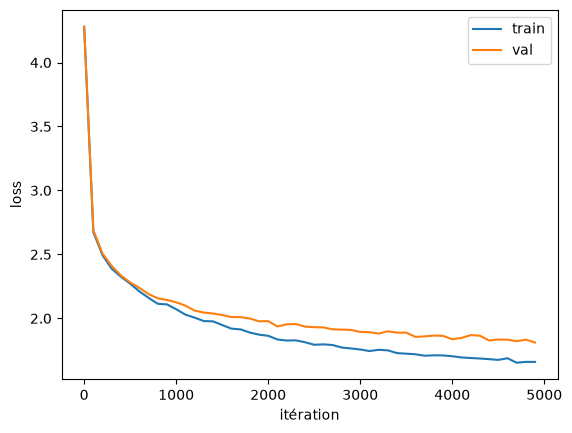


Yest with friend a muble-as in in ere to he.

First Angm:
Now; your threat right, make
A clawarr give of fire one well't,
If we caun a kill your kerch was concity!

YORWISGREY:
Yeare have, best that is death! what you know.

QUEEN VILIZABETH:
Why, all shall a just thy godst of lam'dus puts your forwand
As the blay shere give I am very:
I deveate a net have is late frower:
Though hate love last score:
Fharwer his other Late. Why; thou hast of he.

POLIXENES:
Tencus what gyet there, a do apursed suve a look, our war all diege
Were friend Claudien:
Comns all fowar
of York formore you break.

LUCIO:

GLIUSATILIZI3
WAR:
I'll have my prise hot what see
Thy safe.

KING RICHARRIIIIII:
Reselo dly, quild fhar me,
This quied, now affect, and near live there,
My lord; then soul new, benip brears
She bear anonimy not resome o' not.

YARCIO:
Peach 
AUTIO:
Yhinker have so here were against,
For dure, had not great but a bearly
bell! enen thou laugh.

MAMILIA:
Denthour lady!
Lay as not unshambly to o

In [29]:
import matplotlib.pyplot as plt
it, tr, va = zip(*history)
plt.plot(it, tr, label="train"); plt.plot(it, va, label="val")
plt.xlabel("itération"); plt.ylabel("loss"); plt.legend(); plt.show()

context = torch.zeros((1, 1), dtype=torch.long, device=device)
result = model.generate(context, max_new_tokens=2000)
print(decode(result[0].tolist()))

**Expériences à mener**
1. Comparer le texte avant et après entraînement.
2. Tracer (ci-dessus) ou recopier les losses train/validation.
3. Tester `block_size=16`, puis `64`.
4. Tester 1, puis 4 têtes à `n_embd` constant.
5. Augmenter `dropout` si un surapprentissage apparaît.

**Bilan des quatre TP** — Reliez chaque classe à une notion du cours. Quelle brique crée le contexte ? Laquelle transforme un token ? Laquelle produit les logits ? Où la loss agit-elle sur l'ensemble du modèle ?

**Réponse :**

> L’auto-attention multi-têtes crée le contexte en faisant circuler de l’information entre les tokens. Le MLP transforme ensuite les caractéristiques de chaque token, sans échanger d’information entre eux.
>
> `lm_head` produit les logits sur le vocabulaire. La loss compare ces logits aux tokens cibles, à chaque position, pour ajuster l’ensemble des paramètres du modèle.

> Lien entre les classes et le cours : `nn.Embedding` (token et position) donne la représentation de chaque caractère et de sa place ; `Head` est une tête d'auto-attention ($Q$, $K$, $V$, masque causal, Softmax) ; `MultiHeadAttention` regroupe plusieurs têtes puis les projette avec $W_O$ ; `FeedForward` est le MLP $C\to4C\to C$ ; `LayerNorm` normalise les caractéristiques de chaque token ; `Block` combine attention et MLP avec pré-norm et résiduels ; `lm_head` est l'unembedding vers les logits ; `TransformerLanguageModel` assemble le tout.

> La loss est calculée à la sortie, mais son gradient remonte par rétropropagation à travers `lm_head`, les blocs (grâce aux résiduels) et les embeddings : tous les paramètres sont donc mis à jour.

In [30]:
def run_experiment(n_iters=1000, **cfg):
    """Réentraîne un modèle avec d'autres hyperparamètres (même graine) et renvoie (losses, nb de paramètres).
    Le modèle principal entraîné plus haut est restauré à la fin."""
    g = globals()
    old = {k: g[k] for k in cfg}
    old["model"] = g["model"]
    g.update(cfg)
    assert g["n_embd"] % g["n_head"] == 0

    torch.manual_seed(1337)
    g["model"] = TransformerLanguageModel().to(device)
    opt = torch.optim.AdamW(g["model"].parameters(), lr=learning_rate)
    for _ in range(n_iters):
        xb, yb = get_batch("train")
        _, loss = g["model"](xb, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

    res = estimate_loss()
    n_params = sum(p.numel() for p in g["model"].parameters())
    g.update(old)
    return res, n_params

experiences = {
    "référence (T=32, 4 têtes, dropout=0)": {},
    "block_size=16": {"block_size": 16},
    "block_size=64": {"block_size": 64},
    "1 tête (n_head=1)": {"n_head": 1},
    "dropout=0.2": {"dropout": 0.2},
}

for nom, cfg in experiences.items():
    res, n_params = run_experiment(1000, **cfg)
    print(f"{nom:38s} train {res['train']:.4f} | val {res['val']:.4f} | {n_params} paramètres")

référence (T=32, 4 têtes, dropout=0)   train 2.0600 | val 2.0830 | 209729 paramètres
block_size=16                          train 2.0818 | val 2.1290 | 208705 paramètres
block_size=64                          train 2.0890 | val 2.1143 | 211777 paramètres
1 tête (n_head=1)                      train 2.0291 | val 2.0594 | 209729 paramètres
dropout=0.2                            train 2.1538 | val 2.1685 | 209729 paramètres


**Réponses aux expériences :**

> 1. Avant l'entraînement, le texte généré est une suite de caractères aléatoires sans aucun sens. Après 5 000 étapes, on retrouve la mise en page d'une pièce de théâtre avec noms des persos en majuscules suivis de `:`, retours à la ligne, vers courts, ponctuation et quelques vrais mots anglais (`friend`, `death`, `lord`). Après, beaucoup de mots restent inventés (`RICHARRIIIIII`, `GLIUSATILIZI3`) et le texte n'a pas trop de sens : le modèle a appris le format et une orthographe approximative, pas le sens donc on a globalement du charabia.

> 2. La loss d'entraînement passe de 4,28 à 1,66 et celle de validation de 4,28 à 1,81 (étape 4900). On voit qu'il n'y a pas de surapprentissage net.

> 3. `block_size=16` donne moins de contexte au modèle, donc on s'attend à une loss un peu plus haute, ce qui est marginalement le cas ici. Avec `block_size=64`, le contexte est plus long et la loss devrait être plus basse ce qui est à peu près le cas (faible différence).

> 4. Avec 1 tête de taille 64 ou 4 têtes de taille 16, le nombre de paramètres est le même, car $4\times3\times64\times16=3\times64\times64$. La différence est qu'avec 4 têtes, chaque couche peut calculer 4 motifs d'attention différents. On a une loss légèrement plus basse avec 4 têtes. 

> 5. Il n'y a pas de surapprentissage à corriger ici (la validation baisse encore); Le dropout met aléatoirement à zéro une partie des activations pendant l'entraînement pour limiter la mémorisation. Ici l'écart entre train et validation n'est que d'environ 0,15, donc il n'est pas indispensable. Avec `dropout=0.2`, on a à une loss d'entraînement plus haute et à un écart plus petit ; il deviendrait utile si la loss de validation se mettait à remonter. 

Bilan:

| Classe | Notion | Rôle |
|---|---|---|
| Head / MultiHeadAttention | Self-attention | Contexte : crée la communication entre positions |
| FeedForward | MLP | Calcul : transforme chaque token indépendamment |
| LayerNorm | Normalisation | Stabilise, ne mélange rien |
| Block | Bloc Transformer | Combine communication + calcul avec résiduels |
| token_embedding_table / position_embedding_table | Embeddings | Donnent le sens initial (identité + position) |
| lm_head | Unembedding | Produit les logits finaux sur le vocabulaire |
| F.cross_entropy | Loss | Agit sur l'ensemble du modèle : le gradient qui en découle traverse lm_head, tous les blocs, jusqu'aux embeddings. C'est ce qui met à jour absolument tous les paramètres à chaque pas d'optimisation |